# Solar Power Generation Data Analysis
## Notebook 03 — Plant 2: From Diagnosis to Work Order

**The story so far:** in Plant 2, inverters stop producing while the sun is shining. Outages cost about **22% of the potential energy**, the equivalent of 10 days of production out of 34.

A diagnosis is not yet a decision. The O&M manager and the CFO now ask:

> *"Where do we intervene first, and how much is it worth?"*

### What this notebook shows
1. Turning zero readings into **outage events** (a rule, not a model)
2. **Availability** and lost energy per inverter
3. A **Pareto** view: which events cost the most
4. Losses in **€**
5. A **work list** for the operator

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')
pd.set_option('display.width', None)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

DATA = "../data"
generation_df = pd.read_csv(os.path.join(DATA, "Plant_2_Generation_Data.csv"))
weather_df = pd.read_csv(os.path.join(DATA, "Plant_2_Weather_Sensor_Data.csv"))
for df in (generation_df, weather_df):
    df['DATE_TIME'] = pd.to_datetime(df['DATE_TIME'], format='%Y-%m-%d %H:%M:%S')
generation_df['DAY'] = generation_df['DATE_TIME'].dt.date

# Same selection as Notebook 02: inverters with > 98% completeness
completeness = generation_df.groupby(['SOURCE_KEY', 'DAY']).size().div(96).mul(100).unstack()
high_quality = completeness.mean(axis=1)[lambda s: s > 98].index
generation_df = generation_df[generation_df['SOURCE_KEY'].isin(high_quality)]

# Same definitions as Notebook 02
SUN_THRESHOLD = 0.1     # kW/m²: the sun is shining
ZERO_THRESHOLD = 1.0    # kW: the inverter is not producing
INTERVAL_H = 0.25       # each reading covers 15 minutes

inv = (generation_df.merge(weather_df[['DATE_TIME', 'IRRADIATION']], on='DATE_TIME')
       .sort_values(['SOURCE_KEY', 'DATE_TIME']).reset_index(drop=True))
inv['OUTAGE'] = (inv['DC_POWER'] < ZERO_THRESHOLD) & (inv['IRRADIATION'] > SUN_THRESHOLD)

# What the inverter should have produced: median AC power of the inverters running at that moment
peer_median = inv[inv['DC_POWER'] >= ZERO_THRESHOLD].groupby('DATE_TIME')['AC_POWER'].median()
inv['EXPECTED_AC'] = inv['DATE_TIME'].map(peer_median).fillna(0)

print(f"{inv['SOURCE_KEY'].nunique()} inverters, {inv['OUTAGE'].sum():,} outage readings")

12 inverters, 2,590 outage readings


## 1. From readings to events

The O&M team does not work on 15-minute readings, it works on **events**: *inverter X was down from 10:00 to 14:45*. Consecutive outage readings of the same inverter form one event.

This function **is the alert rule**: run it every day on fresh data and it produces the list of events. 

In [2]:
def detect_outage_events(df):
    # Consecutive outage readings of the same inverter get the same event id
    new_block = (df['OUTAGE'] != df.groupby('SOURCE_KEY')['OUTAGE'].shift()).cumsum()
    events = (df[df['OUTAGE']]
              .groupby(['SOURCE_KEY', new_block[df['OUTAGE']]])
              .agg(START=('DATE_TIME', 'min'),
                   END=('DATE_TIME', 'max'),
                   READINGS=('DATE_TIME', 'size'),
                   LOST_KWH=('EXPECTED_AC', lambda p: (p * INTERVAL_H).sum()))
              .reset_index(level=1, drop=True).reset_index())
    events['DURATION_H'] = events['READINGS'] * INTERVAL_H
    return events.drop(columns='READINGS').sort_values('LOST_KWH', ascending=False).reset_index(drop=True)

events = detect_outage_events(inv)

print(f"Outage events: {len(events)}")
print(f"Duration — median: {events['DURATION_H'].median():.2f} h | "
      f"90th percentile: {events['DURATION_H'].quantile(0.9):.1f} h | max: {events['DURATION_H'].max():.1f} h")
events.head(5).round({'LOST_KWH': 0})

Outage events: 317
Duration — median: 1.25 h | 90th percentile: 5.0 h | max: 8.5 h


,SOURCE_KEY,START,END,LOST_KWH,DURATION_H
0,WcxssY2VbP4hApt,2020-05-22 09:15:00,2020-05-22 17:30:00,8110.0,8.50
1,81aHJ1q11NBPMrL,2020-05-27 07:00:00,2020-05-27 15:00:00,7603.0,8.25
2,xoJJ8DcxJEcupym,2020-05-20 09:15:00,2020-05-20 14:45:00,6531.0,5.75
3,PeE6FRyGXUgsRhN,2020-05-20 09:30:00,2020-05-20 14:45:00,6320.0,5.50
4,9kRcWv60rDACzjR,2020-05-27 09:30:00,2020-05-27 15:00:00,6298.0,5.75


> More than 300 events in 34 days. Half last less than ~1.25 hours, but one in ten lasts **5 hours or more**: entire middays lost.

## 2. Availability and lost energy per inverter

**Availability** is the share of time the equipment is able to produce when it should. We compute it over the sunny readings:

$$\text{Availability} = 1 - \frac{\text{outage readings}}{\text{sunny readings}}$$

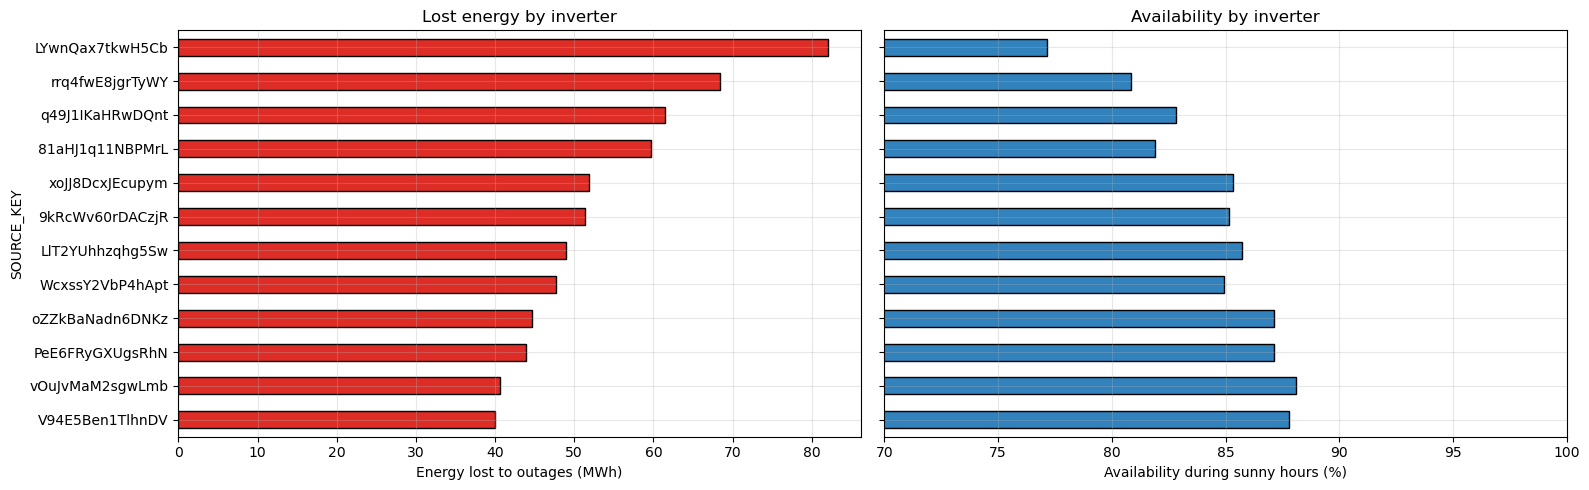

,AVAILABILITY_%,EVENTS,LOST_MWH
SOURCE_KEY,,,
LYwnQax7tkwH5Cb,77.2,31,82.1
rrq4fwE8jgrTyWY,80.8,34,68.4
q49J1IKaHRwDQnt,82.8,28,61.4
81aHJ1q11NBPMrL,81.9,37,59.7
xoJJ8DcxJEcupym,85.3,28,51.9
9kRcWv60rDACzjR,85.1,20,51.3
LlT2YUhhzqhg5Sw,85.7,22,49.0
WcxssY2VbP4hApt,84.9,19,47.6
oZZkBaNadn6DNKz,87.1,24,44.7


In [3]:
sunny = inv[inv['IRRADIATION'] > SUN_THRESHOLD]
scorecard = pd.DataFrame({
    'AVAILABILITY_%': (1 - sunny.groupby('SOURCE_KEY')['OUTAGE'].mean()) * 100,
    'EVENTS': events.groupby('SOURCE_KEY').size(),
    'LOST_MWH': events.groupby('SOURCE_KEY')['LOST_KWH'].sum() / 1000,
}).sort_values('LOST_MWH', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
scorecard['LOST_MWH'].plot(kind='barh', ax=axes[0], color='#de2d26', edgecolor='black')
axes[0].set_xlabel('Energy lost to outages (MWh)')
axes[0].set_title('Lost energy by inverter')
scorecard['AVAILABILITY_%'].plot(kind='barh', ax=axes[1], color='#3182bd', edgecolor='black')
axes[1].set_xlabel('Availability during sunny hours (%)')
axes[1].set_title('Availability by inverter')
axes[1].set_xlim(70, 100)
axes[1].set_ylabel('')
axes[0].invert_yaxis()   # worst inverter on top
plt.tight_layout()
plt.show()

scorecard.round(1)

> All inverters are affected, but not equally: availability ranges from about 77% to 88%, and **the worst inverter loses twice the energy of the best one**. The ranking tells O&M where to look first.

## 3. Pareto: which events cost the most?

Do we need to chase all 300+ events? We sort them from the most to the least costly and look at the cumulative share of lost energy.

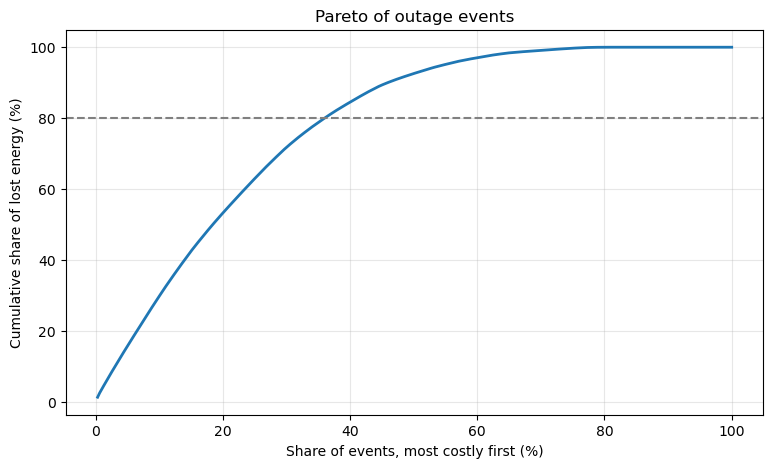

,EVENTS,LOST_MWH,SHARE_OF_EVENTS_%,SHARE_OF_LOSS_%
LENGTH,,,,
Long (≥ 2 h),135,556.5,42.6,86.9
Short (< 2 h),182,84.1,57.4,13.1


In [4]:
ranked = events.sort_values('LOST_KWH', ascending=False).reset_index(drop=True)
cum_share = ranked['LOST_KWH'].cumsum() / ranked['LOST_KWH'].sum() * 100
event_share = (np.arange(1, len(ranked) + 1)) / len(ranked) * 100

plt.figure(figsize=(9, 5))
plt.plot(event_share, cum_share, linewidth=2)
plt.axhline(80, color='grey', linestyle='--')
plt.xlabel('Share of events, most costly first (%)')
plt.ylabel('Cumulative share of lost energy (%)')
plt.title('Pareto of outage events')
plt.show()

ranked['LENGTH'] = np.where(ranked['DURATION_H'] >= 2, 'Long (≥ 2 h)', 'Short (< 2 h)')
split = ranked.groupby('LENGTH').agg(EVENTS=('LOST_KWH', 'size'), LOST_MWH=('LOST_KWH', lambda x: x.sum() / 1000))
split['SHARE_OF_EVENTS_%'] = split['EVENTS'] / split['EVENTS'].sum() * 100
split['SHARE_OF_LOSS_%'] = split['LOST_MWH'] / split['LOST_MWH'].sum() * 100
split.round(1)

> **Long outages (2 hours or more) are less than half of the events but almost 90% of the lost energy.** Short trips are annoying, long ones are expensive. The priority is clear: find out why some inverters stay down for hours, and shorten the time to restart.

## 4. How much is it worth?

Lost revenue = lost energy × price. The price depends on the market and the contract (spot price, PPA, incentive), so we keep it as a **parameter** and look at a range.

In [6]:
lost_mwh_total = events['LOST_KWH'].sum() / 1000
print(f"Lost energy in {inv['DAY'].nunique()} days: {lost_mwh_total:,.0f} MWh")
print(f"Every 1 €/MWh of price = {lost_mwh_total:,.0f} € of lost revenue\n")

prices = [25, 50, 75, 100]   # €/MWh, illustrative range: replace with your market or contract price
value = pd.DataFrame({'PRICE_EUR_MWH': prices,
                      'LOST_REVENUE_EUR': [int(round(lost_mwh_total * p, -3)) for p in prices]})
value

Lost energy in 34 days: 641 MWh
Every 1 €/MWh of price = 641 € of lost revenue



,PRICE_EUR_MWH,LOST_REVENUE_EUR
0,25,16000
1,50,32000
2,75,48000
3,100,64000


> The formula is the message: **€ lost = MWh lost × price**. The data science gives the MWh; the market or the contract gives the price.
>
> ⚠️ These are 34 days in May–June, high-sun months. Annualising would need a full year of data: solar production is seasonal.

## 5. The deliverable: a work list for O&M

The last phase of the data science lifecycle is **deployment**: turning analysis into something people use. Here it is a simple file the operator can open in Excel, with the most costly events first.

In [7]:
work_list = ranked[ranked['LENGTH'] == 'Long (≥ 2 h)'][['SOURCE_KEY', 'START', 'END', 'DURATION_H', 'LOST_KWH']].copy()
work_list['LOST_KWH'] = work_list['LOST_KWH'].round(0)
work_list.to_csv('om_work_list.csv', index=False)

print(f"Work list: {len(work_list)} long events, {work_list['LOST_KWH'].sum() / 1000:,.0f} MWh lost → saved to om_work_list.csv")
work_list.head(10)

Work list: 135 long events, 556 MWh lost → saved to om_work_list.csv


,SOURCE_KEY,START,END,DURATION_H,LOST_KWH
0,WcxssY2VbP4hApt,2020-05-22 09:15:00,2020-05-22 17:30:00,8.50,8110.0
1,81aHJ1q11NBPMrL,2020-05-27 07:00:00,2020-05-27 15:00:00,8.25,7603.0
2,xoJJ8DcxJEcupym,2020-05-20 09:15:00,2020-05-20 14:45:00,5.75,6531.0
3,PeE6FRyGXUgsRhN,2020-05-20 09:30:00,2020-05-20 14:45:00,5.50,6320.0
4,9kRcWv60rDACzjR,2020-05-27 09:30:00,2020-05-27 15:00:00,5.75,6298.0
5,vOuJvMaM2sgwLmb,2020-05-27 09:30:00,2020-05-27 15:00:00,5.75,6298.0
6,WcxssY2VbP4hApt,2020-05-27 09:30:00,2020-05-27 15:00:00,5.75,6298.0
7,rrq4fwE8jgrTyWY,2020-05-23 09:30:00,2020-05-23 14:30:00,5.25,6055.0
8,LYwnQax7tkwH5Cb,2020-05-23 09:30:00,2020-05-23 14:30:00,5.25,6055.0
9,vOuJvMaM2sgwLmb,2020-05-22 09:30:00,2020-05-22 14:30:00,5.25,6038.0


### One more clue in the work list
Some of the most costly events start and end **at exactly the same time on different inverters**. Let's group them.

In [8]:
work_list['WINDOW'] = work_list['START'].dt.strftime('%d %b %H:%M') + ' → ' + work_list['END'].dt.strftime('%H:%M')
shared = (work_list.groupby('WINDOW')
          .agg(INVERTERS=('SOURCE_KEY', 'nunique'), LOST_MWH=('LOST_KWH', lambda x: x.sum() / 1000))
          .query('INVERTERS > 1')
          .sort_values('LOST_MWH', ascending=False))
shared.head(6).round(1)

,INVERTERS,LOST_MWH
WINDOW,,
27 May 09:30 → 15:00,3,18.9
07 Jun 09:30 → 15:15,3,17.2
21 May 10:00 → 13:15,4,15.9
05 Jun 10:00 → 13:30,4,15.6
23 May 09:30 → 14:30,2,12.1
08 Jun 09:45 → 15:00,2,11.9


> Groups of 2–4 inverters go down and come back **at the same minute**. Independent faults would not be synchronised like this. It points to something they **share**: a common transformer, a plant-level control action, or an event on the grid side.
>
> That is the first question for the operator, and the cheapest one to answer: **which inverters share the same electrical path?**

## Wrap-up

| Question | Answer |
|---|---|
| What is wrong? | Inverters stop under full sun: ~22% of potential energy lost |
| Where? | Every inverter, availability 77–88%; the worst loses 2× the best |
| What matters most? | Long outages (≥ 2 h): less than half of the events, almost 90% of the loss |
| How much is it worth? | Lost MWh × price: the formula, with the price owned by the business |
| What do we hand over? | A daily alert rule and a prioritised work list |
| What do we ask first? | Why groups of inverters stop and restart at the same minute |

**From raw data to a work order in three notebooks, without a single machine learning model.**

**Next:** forecasting. A model trained on this data will learn that the plant "underperforms at noon". Can it still predict tomorrow's production, and what does its error cost?